<div style="display: flex; justify-content: space-between; align-items: flex-start; border-bottom: 2px solid #555555; padding-bottom: 15px; margin-bottom: -8px;">
    <div style="width: 50%;">
        <h2>
            <span style="color: #B30033;">▍</span>TRABAJO DE FIN DE MÁSTER
        </h2>
        <h1 style="margin-top: -10px;">
            Creación de un framework para recomendar las personas más adecuadas para trabajar en un determinado proyecto de ingeniería del software
        </h1>
    </div>
    <div style="width: 50%; text-align: right;">
        <div style="display: flex; justify-content: space-between; align-items: flex-start; margin-top: 30px;">
            <div style="width: 20%;"></div>
            <div style="width: 80%; border-left: 2px solid #555555; padding-left: 20px;">
                <div style="margin-bottom: 20px;">
                    <p style="margin: 0; font-size: 1.4em; font-weight: bold;">
                        Profesores
                    </p>
                </div>
                <div style="margin-top: 8px; text-align: right;">
                    <span style="display: block; font-size: 1em; color: #D0D0D0;">
                        Aurora Vizcaíno Barcelo
                    </span>
                    <span style="display: block; font-size: 1em; color: #D0D0D0; margin-top: 5px;">
                        Julio Alberto López Gómez
                    </span>
                </div>
            </div>
        </div>
    </div>
</div>

<div style="margin-top: 30px; padding: 20px; background-color: rgba(179, 0, 51, 0.05); border-left: 4px solid #B30033; border-radius: 4px;">
    <h3 style="margin-top: 0; color: #B30033;">🎯 Objetivo de esta Libreta (Fase 3: Entrenamiento del Autoencoder)</h3>
    <p style="font-size: 1.1em; line-height: 1.6; color: #E0E0E0;">
        Una vez superada la fase de ingeniería de datos, el objetivo de esta tercera libreta sería <strong>construir, entrenar y validar nuestra Red Neuronal Profunda</strong>. Utilizaremos la librería PyTorch para diseñar una arquitectura simétrica capaz de extraer la esencia pura de cada desarrollador.
    </p>
    <ul style="font-size: 1.1em; line-height: 1.6; color: #D0D0D0; margin-bottom: 0;">
        <li><strong>Configuración Simétrica:</strong> Crearemos el <em>Encoder</em> y el <em>Decoder</em> implementando funciones de activación <strong>ReLU</strong> y una capa final <strong>Sigmoide</strong> alineada a nuestros datos escalados [0, 1].</li>
        <li><strong>Prevención del Overfitting:</strong> Implementaremos estrategias de robustez como <strong>Dropout (20%)</strong> y regularización L2.</li>
        <li><strong>Optimización Empírica:</strong> Evaluaremos diferentes configuraciones del Espacio Latente (16 vs 32 dimensiones) para demostrar matemáticamente cuál es el "ADN" óptimo para NetSTAFF.</li>
    </ul>
</div>
<br/>

<div style="border-bottom: 2px solid #555555; padding-bottom: 25px; margin-bottom: 10px">
    <div style="display: flex; align-items: center; margin-bottom: 10px;">
        <span style="color: #B30033; font-size: 1.5em; margin-right: 10px;">▍</span>
        <h3 style="margin: 0; font-size: 1.4em; font-weight: bold">
            Realizado por Miguel Ángel Sánchez-Medina Camacho <span style="font-size: 0.7em; font-style: italic; font-weight: normal;"></span>
        </h3>
    </div>
</div>

### 3.1. Configuración del Entorno y carga de datos matriciales

Para esta primera celda importamos las librerías necesarias de **PyTorch**. A continuación, cargamos nuestra matriz procesada de +35k candidatos. Es muy importanto recordar que, para este punto, nuestras 217 variables ya han pasado por una binarización estricta y un escalado *MinMax*, por lo que todas las métricas están comprendidas entre 0 y 1. De esta forma, contamos con un ecosistema matemático homogéneo perfecto para que el Autoencoder no sufra sesgos de magnitud.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import torch
from torch.utils.data import DataLoader

os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

sys.path.append(os.path.abspath(os.path.join('../..')))
from src.hard_skills import config, model_utils

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Dispositivo: {device}")

df_model = pd.read_csv(config.MODEL_MATRIX_PATH, index_col='CandidateId')
X_numpy = df_model.values
print(f"Forma de los datos: {X_numpy.shape}")

Dispositivo: cuda
Forma de los datos: (35288, 217)


### 3.2. Estrategia de Validación (Split 80/20)

Siguiendo los estándares comentados en la teoría de la asignatura, aquí vamos a dividir nuestro dataset: el **80% de los perfiles** se utilizará en la fase de entrenamiento (*Train*) para ajustar los pesos de las neuronas, y el **20% restante** se aislará para la validación (*Validation*). Esto nos permite comprobar de forma empírica que la red aprende a generalizar conceptos técnicos y no se limita a "memorizar" a los candidatos.

Además, empaquetamos los tensores en objetos `DataLoader` utilizando lotes (*batches* de 64), lo que estabiliza la convergencia del optimizador Adam.

In [2]:
X_train, X_val = train_test_split(X_numpy, test_size=0.2, random_state=42)
tensor_train = torch.tensor(X_train, dtype=torch.float32)
tensor_val = torch.tensor(X_val, dtype=torch.float32)
train_loader = DataLoader(tensor_train, batch_size=64, shuffle=True)
val_loader = DataLoader(tensor_val, batch_size=64, shuffle=False)

print(f"Muestras de entrenamiento: {len(X_train)} | Validación: {len(X_val)}")

Muestras de entrenamiento: 28230 | Validación: 7058


### 3.3. Entrenamiento y búsqueda de hiperparámetros

Aquí ejecutamos el motor de aprendizaje de NetSTAFF. Para demostrar empíricamente cuál es la mejor configuración arquitectónica, lanzamos un bucle de búsqueda probando combinaciones de Tasa de Aprendizaje (*Learning Rate*) y tamaño del "cuello de botella" o **Espacio Latente (16 dimensiones)**.

*Nota técnica: El entrenamiento tiene un máximo de 50 épocas y cuenta con un mecanismo de guardado automático (Early Stopping manual) que captura siempre la configuración de pesos que haya minimizado el Error Cuadrático Medio (MSE) en los datos de validación.*

In [3]:
input_dim = X_train.shape[1]
learning_rates = [0.001, 0.005]
latent_dims = [16]

mejor_val_loss_global = float('inf')
mejor_configuracion = {}
mejor_modelo_global = None
mejores_train_losses = []
mejores_val_losses = []

print("Iniciando búsqueda de hiperparámetros...\n")

for lr in learning_rates:
    for lat_dim in latent_dims:
        print(f"Probando configuración: LR={lr} | Latent_Dim={lat_dim}")
        
        modelo_prueba = model_utils.CandidateAutoencoder(input_dim=input_dim, latent_dim=lat_dim).to(device)
        modelo_entrenado, train_losses, val_losses = model_utils.entrenar_autoencoder(
            modelo=modelo_prueba,
            train_loader=train_loader,
            val_loader=val_loader,
            epochs=50,
            lr=lr,
            weight_decay=1e-4,
            device=device
        )
        
        min_val_loss = min(val_losses)
        print(f"Mejor MSE de Validación para esta config: {min_val_loss:.4f}\n")
        
        if min_val_loss < mejor_val_loss_global:
            mejor_val_loss_global = min_val_loss
            mejor_configuracion = {'lr': lr, 'latent_dim': lat_dim}
            mejor_modelo_global = modelo_entrenado
            mejores_train_losses = train_losses
            mejores_val_losses = val_losses

print("========================================")
print(f"LA MEJOR CONFIGURACIÓN FUE: {mejor_configuracion}")
print(f"CON UN ERROR (MSE) DE: {mejor_val_loss_global:.4f}")
print("========================================")

Iniciando búsqueda de hiperparámetros...

Probando configuración: LR=0.001 | Latent_Dim=16
Epoch [01/50] | Train MSE: 0.0817 | Val MSE: 0.0666
Epoch [05/50] | Train MSE: 0.0631 | Val MSE: 0.0612
Epoch [10/50] | Train MSE: 0.0623 | Val MSE: 0.0609
Epoch [15/50] | Train MSE: 0.0617 | Val MSE: 0.0601
Epoch [20/50] | Train MSE: 0.0613 | Val MSE: 0.0598
Epoch [25/50] | Train MSE: 0.0611 | Val MSE: 0.0595
Epoch [30/50] | Train MSE: 0.0609 | Val MSE: 0.0593
Epoch [35/50] | Train MSE: 0.0608 | Val MSE: 0.0592
Epoch [40/50] | Train MSE: 0.0607 | Val MSE: 0.0592
Epoch [45/50] | Train MSE: 0.0607 | Val MSE: 0.0593
Epoch [50/50] | Train MSE: 0.0605 | Val MSE: 0.0591
Finalizado entrenamiento. Mejor Val MSE: 0.0590
Mejor MSE de Validación para esta config: 0.0590

Probando configuración: LR=0.005 | Latent_Dim=16
Epoch [01/50] | Train MSE: 0.0768 | Val MSE: 0.0712
Epoch [05/50] | Train MSE: 0.0687 | Val MSE: 0.0685
Epoch [10/50] | Train MSE: 0.0683 | Val MSE: 0.0674
Epoch [15/50] | Train MSE: 0.0682 

### 3.4. Análisis de convergencia y exportación del Modelo

Para este apartado, evaluamos visualmente el rendimiento del modelo ganador mediante las curvas de aprendizaje. Si observamos la gráfica, vemos una caída suave y paralela de las líneas de *Train MSE* y *Validation MSE*, lo que nos confirma la ausencia de *Overfitting*, justificando el éxito de nuestra regularización y Dropout.

Finalmente, una vez que la red ha demostrado su capacidad para comprimir los perfiles en un vector latente de **16 dimensiones** con un error mínimo, exportamos los "engranajes" de la red (su `state_dict` en formato `.pth`). Esto nos permite desplegar el modelo en producción (Inferencia) sin necesidad de volver a entrenarlo nunca más.

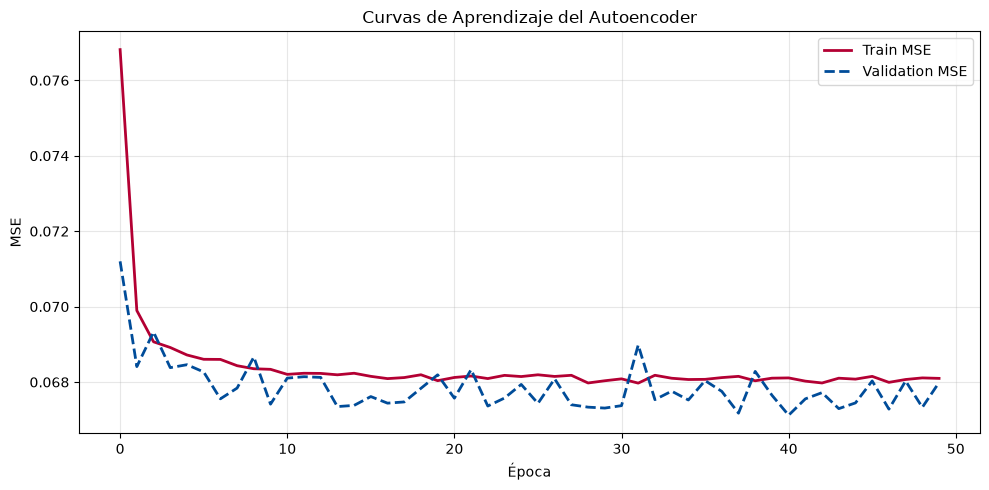

Modelo guardado en: ../models/autoencoder_candidatos.pth


In [4]:
# Curva de aprendizaje
plt.figure(figsize=(10, 5))
plt.plot(train_losses, label='Train MSE', color='#B30033', linewidth=2)
plt.plot(val_losses, label='Validation MSE', color='#004C99', linewidth=2, linestyle='--')
plt.title('Curvas de Aprendizaje del Autoencoder')
plt.xlabel('Época')
plt.ylabel('MSE')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

os.makedirs('../models', exist_ok=True)
ruta_modelo = '../models/autoencoder_candidatos.pth'
torch.save(mejor_modelo_global.state_dict(), ruta_modelo)
print(f"Modelo guardado en: {ruta_modelo}")